# Assignment: Neural Machine Translation (DE → EN) with Seq2Seq: RNN vs LSTM vs GRU
**Course:** Advanced Deep Learning: *Recurrent Neural Network (RNN) & LSTM*, slide 59
**Name:** ______________   **Student ID:** ______________

**Task (from the slide)**
1. Data: the **DE-EN News Commentary** parallel corpus from WMT13 (`training-parallel-nc-v8.tgz`).
2. Model: an **Encoder-Decoder (Seq2Seq)** translation system (slides 53 to 57).
3. Compare **three recurrent cells (RNN, LSTM, GRU)** on:
   * translation quality, measured with **BLEU**;
   * **convergence**: when the model starts to converge, shown with loss-function graphs;
   * **computation time**.

**How the notebook is organised**

| § | Content |
|---|---------|
| 0 | Setup & configuration (all hyper-parameters in one place, identical for the three cells, so the comparison is fair) |
| 1 | Data: download, clean, split, tokenise, build vocabularies |
| 2 | Model: Encoder → encoder vector → Decoder, with the cell type as a parameter |
| 3 | Training loop: teacher forcing, gradient clipping, timing, early stopping |
| 4 | Evaluation: greedy decoding + corpus BLEU (NLTK, as in the linked tutorial, plus sacreBLEU as a cross-check) |
| 5 | Run the three experiments |
| 6 | Results: loss curves / convergence, time, BLEU, sample translations |
| 7 | Extra: measuring the vanishing gradient (slides 23 to 25, 30 to 33, 44 to 49) |
| 8 | Discussion |

> **Hardware:** use a GPU (Google Colab → *Runtime → Change runtime type → T4 GPU*). With the default config, each model
> takes roughly 10 to 25 minutes on a T4. On CPU, set `FAST = True` first.

## 0. Setup

In [1]:
# Colab already has torch / numpy / matplotlib / pandas / nltk; sacrebleu usually needs installing.
import importlib, subprocess, sys
for pkg in ["sacrebleu", "nltk"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import os, re, gzip, html, json, math, time, random, tarfile, collections, urllib.request
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
import matplotlib.pyplot as plt
import sacrebleu
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")

torch 2.14.1+cu130 | device: cpu 


### Configuration
All three models share **exactly the same** data, vocabulary, embedding size, hidden size, depth, optimiser, learning rate,
batch size, number of epochs and random seed. **Only the recurrent cell changes**, so any difference in the results
comes from the cell itself.

Design choices (and why):
* **Sentence length ≤ 30 tokens.** News Commentary v8 DE-EN has 178,221 lines. After removing duplicates and empty lines,
  ~116k pairs have ≤ 30 tokens on both sides (≈112k for training after the valid/test split), and the rest are long sentences. A plain seq2seq model squeezes the whole source into **one fixed vector** (slide 55), so very
  long sentences mostly add training time without adding BLEU.
* **Reversed source** (Sutskever et al., 2014). The first source words end up close to the first target words, which
  shortens the gradient path, a cheap trick that matters most for the vanilla RNN.
* **Encoder vector fed to every decoder step** (Cho et al., 2014, the paper that introduced the GRU on slide 50). The
  decoder doesn't have to carry the source information in its own state alone. Set `feed_context=False` for the
  "pure" slide-56 decoder.
* **Gradient clipping** (slide 14: exploding gradients) and **teacher forcing** during training.
* `FAST = True` gives a small configuration for a CPU or a quick sanity check.

In [3]:
FAST = True          # True -> tiny run (CPU / debugging)

CFG = dict(
    dataset      = "nc-v8",     # "nc-v8" = WMT13 News Commentary v8 (the assignment) | "multi30k" = small sanity-check corpus
    data_dir     = "/home/user/data",
    max_len      = 30,          # keep pairs whose source AND target have 1..max_len tokens
    max_train    = 150_000,     # cap on training pairs (None = all)
    n_valid      = 2_000,
    n_test       = 2_000,
    min_freq     = 3,           # words seen fewer times -> <unk>
    max_vocab    = 30_000,      # per language
    reverse_src  = True,
    feed_context = True,
    emb          = 256,
    hidden       = 512,
    layers       = 2,
    dropout      = 0.3,
    batch        = 128,
    lr           = 1e-3,
    clip         = 1.0,
    epochs       = 15,
    patience     = 4,           # early stopping on validation loss (None = always run all epochs)
    amp          = True,        # mixed precision on GPU (ignored on CPU)
    seed         = 42,
    cells        = ["rnn", "lstm", "gru"],
    out_dir      = "runs",
)
if FAST:
    CFG.update(max_train=20_000, n_valid=500, n_test=500, max_len=20, max_vocab=8_000,
               emb=128, hidden=256, layers=1, epochs=6, batch=64)

USE_AMP = CFG["amp"] and DEV.type == "cuda"
os.makedirs(CFG["out_dir"], exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])
CFG

{'dataset': 'nc-v8',
 'data_dir': '/home/user/data',
 'max_len': 20,
 'max_train': 20000,
 'n_valid': 500,
 'n_test': 500,
 'min_freq': 3,
 'max_vocab': 8000,
 'reverse_src': True,
 'feed_context': True,
 'emb': 128,
 'hidden': 256,
 'layers': 1,
 'dropout': 0.3,
 'batch': 64,
 'lr': 0.001,
 'clip': 1.0,
 'epochs': 6,
 'patience': 4,
 'amp': True,
 'seed': 42,
 'cells': ['rnn', 'lstm', 'gru'],
 'out_dir': 'runs'}

## 1. Data
`training-parallel-nc-v8.tgz` (from the WMT13 page linked on the slide) contains
`training/news-commentary-v8.de-en.de` and `training/news-commentary-v8.de-en.en`, aligned line by line.
If the download is blocked, download the file manually and put it, or the two extracted files
`news-commentary-v8.de-en.de` / `news-commentary-v8.de-en.en`, in `data/` (on Colab: upload them into a `data` folder).

In [4]:
NC_URLS = ["https://www.statmt.org/wmt13/training-parallel-nc-v8.tgz",
           "http://www.statmt.org/wmt13/training-parallel-nc-v8.tgz"]
M30K = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/{}.{}.gz"

def read_lines(path, opener=open):
    with opener(path, "rt", encoding="utf-8", newline="\n") as f:
        return [l.rstrip("\r\n") for l in f.read().split("\n")]

def load_nc_v8(d):
    os.makedirs(d, exist_ok=True)
    paths = {l: os.path.join(d, f"news-commentary-v8.de-en.{l}") for l in ("de", "en")}
    if not all(os.path.exists(p) for p in paths.values()):
        tgz = os.path.join(d, "training-parallel-nc-v8.tgz")
        if not os.path.exists(tgz):
            for url in NC_URLS:
                try:
                    print("downloading", url); urllib.request.urlretrieve(url, tgz); break
                except Exception as e:
                    print("  failed:", e)
            else:
                raise RuntimeError("Download failed: put training-parallel-nc-v8.tgz in " + d)
        with tarfile.open(tgz) as tar:
            for m in tar.getmembers():
                for l, p in paths.items():
                    if m.name.endswith(os.path.basename(p)):
                        with tar.extractfile(m) as f, open(p, "wb") as g:
                            g.write(f.read())
    de, en = read_lines(paths["de"]), read_lines(paths["en"])
    assert len(de) == len(en), (len(de), len(en))
    return list(zip(de, en))

def load_multi30k(d):
    os.makedirs(d, exist_ok=True)
    out = {}
    for split, name in [("train", "train"), ("valid", "val"), ("test", "test_2016_flickr")]:
        cols = []
        for l in ("de", "en"):
            p = os.path.join(d, f"{name}.{l}.gz")
            if not os.path.exists(p):
                urllib.request.urlretrieve(M30K.format(name, l), p)
            cols.append(read_lines(p, gzip.open))
        out[split] = list(zip(*cols))
    return out

raw = load_nc_v8(CFG["data_dir"]) if CFG["dataset"] == "nc-v8" else load_multi30k(CFG["data_dir"])
print({k: len(v) for k, v in raw.items()} if isinstance(raw, dict) else f"{len(raw):,} raw sentence pairs")

178,222 raw sentence pairs


### Tokenisation, cleaning and splitting
* Lower-case, unescape HTML entities, and split into words and punctuation (`\w` is Unicode-aware, so *für*, *Straße* and
  *Größe* stay single tokens).
* Drop empty pairs, exact duplicates and pairs longer than `max_len`.
* Random **train / valid / test** split with a fixed seed. The test set is never used for training or model selection
  (model selection uses the validation loss).

In [5]:
TOKEN_RE = re.compile(r"\w+(?:['’\-]\w+)*|[^\w\s]")
def tokenize(s):
    return TOKEN_RE.findall(html.unescape(s).lower())

def clean(pairs, max_len):
    out, seen = [], set()
    for de, en in pairs:
        key = (de.strip(), en.strip())
        if key in seen: continue
        seen.add(key)
        s, t = tokenize(de), tokenize(en)
        if 1 <= len(s) <= max_len and 1 <= len(t) <= max_len:
            out.append((s, t))
    return out

rng = random.Random(CFG["seed"])
if isinstance(raw, dict):                      # multi30k comes pre-split
    splits = {k: clean(v, CFG["max_len"]) for k, v in raw.items()}
else:
    data = clean(raw, CFG["max_len"]); rng.shuffle(data)
    nt, nv = CFG["n_test"], CFG["n_valid"]
    splits = dict(test=data[:nt], valid=data[nt:nt + nv], train=data[nt + nv:])
if CFG["max_train"]:
    splits["train"] = splits["train"][:CFG["max_train"]]
for k, v in splits.items():
    print(f"{k:5s}: {len(v):7,} pairs | mean len de {np.mean([len(s) for s,_ in v]):.1f}  en {np.mean([len(t) for _,t in v]):.1f}")
print("\nexample:", " ".join(splits["train"][0][0]), "\n     -> ", " ".join(splits["train"][0][1]))

test :     500 pairs | mean len de 13.5  en 13.4
valid:     500 pairs | mean len de 13.6  en 13.4
train:  20,000 pairs | mean len de 13.5  en 13.3

example: der import von rechtssystemen und gesetzesstandards dominiert die bemühungen früherer kommunistischer länder , sich an den westen anzuschließen . 
     ->  importing laws and legal standards has dominated attempts by former communist countries to join the west .


In [6]:
PAD, BOS, EOS, UNK = 0, 1, 2, 3
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]

class Vocab:
    # Built from the TRAINING split only, so no information leaks from the valid/test sets.
    def __init__(self, sents, min_freq, max_size):
        cnt = collections.Counter(w for s in sents for w in s)
        words = [w for w, n in cnt.most_common(max_size) if n >= min_freq]
        self.itos = SPECIALS + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        covered = sum(cnt[w] for w in words)
        self.coverage = covered / sum(cnt.values())
    def __len__(self): return len(self.itos)
    def encode(self, toks): return [self.stoi.get(w, UNK) for w in toks]
    def decode(self, ids):
        out = []
        for i in ids:
            if i == EOS: break
            if i not in (PAD, BOS): out.append(self.itos[i])
        return out

src_vocab = Vocab([s for s, _ in splits["train"]], CFG["min_freq"], CFG["max_vocab"])
tgt_vocab = Vocab([t for _, t in splits["train"]], CFG["min_freq"], CFG["max_vocab"])
print(f"DE vocab {len(src_vocab):,} (covers {src_vocab.coverage:.1%} of training tokens)")
print(f"EN vocab {len(tgt_vocab):,} (covers {tgt_vocab.coverage:.1%} of training tokens)")

DE vocab 8,004 (covers 90.7% of training tokens)
EN vocab 7,095 (covers 94.8% of training tokens)


### Batching
Each example is `(source ids, target ids)`. The target gets `<bos> … <eos>`. The decoder **input** is the target
without its last token, and the decoder **output** (what it must predict) is the target shifted one step left.
Batches group sentences of similar length to reduce padding, and padded steps are skipped with `pack_padded_sequence`
in the encoder and `ignore_index=PAD` in the loss.

In [7]:
def to_examples(pairs):
    ex = []
    for s, t in pairs:
        src = src_vocab.encode(s)
        if CFG["reverse_src"]: src = src[::-1]
        ex.append((torch.tensor(src), torch.tensor([BOS] + tgt_vocab.encode(t) + [EOS])))
    return ex

def collate(batch):
    src, tgt = zip(*batch)
    return (pad_sequence(src, batch_first=True, padding_value=PAD),
            torch.tensor([len(s) for s in src]),
            pad_sequence(tgt, batch_first=True, padding_value=PAD))

def batches(examples, bs, shuffle, seed=0):
    # Length-bucketed batches: shuffle, sort inside chunks of 50 batches, then shuffle the batch order.
    idx = list(range(len(examples)))
    r = random.Random(seed)
    if shuffle: r.shuffle(idx)
    out = []
    for i in range(0, len(idx), bs * 50):
        chunk = sorted(idx[i:i + bs * 50], key=lambda j: len(examples[j][0]))
        out += [chunk[k:k + bs] for k in range(0, len(chunk), bs)]
    if shuffle: r.shuffle(out)
    for b in out:
        yield collate([examples[j] for j in b])

train_ex, valid_ex, test_ex = (to_examples(splits[k]) for k in ("train", "valid", "test"))
src, src_len, tgt = next(batches(train_ex, 4, True))
print("src", tuple(src.shape), "lens", src_len.tolist(), "\ntgt", tuple(tgt.shape))

src (4, 17) lens [16, 17, 17, 17] 
tgt (4, 20)


## 2. Model: Encoder → encoder vector → Decoder (slides 53 to 57)

| Part | Slide | Implementation |
|---|---|---|
| **Encoder** | 54: $h_t = f(W^{(hh)}h_{t-1} + W^{(hx)}x_t)$ | embedding + stacked recurrent layer that reads the (reversed) German sentence |
| **Encoder vector** | 55: the final hidden state | the encoder's final state (for LSTM: both $h$ and $c$) becomes the decoder's **initial state** |
| **Decoder** | 56: $h_t = f(W^{(hh)}h_{t-1})$ | stacked recurrent layer whose input is the previous English word (teacher forcing) plus the encoder vector |
| **Output** | 57: $y_t = \mathrm{softmax}(W^S h_t)$ | linear layer → softmax over the English vocabulary (the softmax sits inside the cross-entropy loss) |

The **only** thing that changes between experiments is `cell`:
* `rnn`: $h_t=\tanh(W_x x_t + W_h h_{t-1} + b)$, one weight block
* `lstm`: forget / input / output gates + cell state $C_t$ (slides 35 to 43), four weight blocks
* `gru`: update and reset gates, no separate cell state (slides 50 and 51), three weight blocks

In [8]:
CELL = {"rnn": lambda *a, **k: nn.RNN(*a, nonlinearity="tanh", **k), "lstm": nn.LSTM, "gru": nn.GRU}

def top_hidden(state):
    # Last layer's hidden state h from an RNN/GRU state (layers,B,H) or an LSTM state (h, c).
    h = state[0] if isinstance(state, tuple) else state
    return h[-1]                                                        # (B, H)

class Encoder(nn.Module):
    def __init__(self, cell, V, E, H, layers, p):
        super().__init__()
        self.emb  = nn.Embedding(V, E, padding_idx=PAD)
        self.rnn  = CELL[cell](E, H, layers, batch_first=True, dropout=p if layers > 1 else 0.0)
        self.drop = nn.Dropout(p)
    def forward_emb(self, e, src_len):                                  # e: (B, S, E)
        packed = pack_padded_sequence(e, src_len.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.rnn(packed)                                     # (layers, B, H) [x2 for LSTM]
        return state
    def forward(self, src, src_len):
        return self.forward_emb(self.drop(self.emb(src)), src_len)

class Decoder(nn.Module):
    def __init__(self, cell, V, E, H, layers, p, feed_context):
        super().__init__()
        self.feed_context = feed_context
        self.emb  = nn.Embedding(V, E, padding_idx=PAD)
        self.rnn  = CELL[cell](E + (H if feed_context else 0), H, layers, batch_first=True,
                               dropout=p if layers > 1 else 0.0)
        self.drop = nn.Dropout(p)
        self.out  = nn.Linear(H, V)
    def forward(self, y_in, state, context):                            # y_in: (B, T)
        e = self.drop(self.emb(y_in))                                   # (B, T, E)
        if self.feed_context:
            e = torch.cat([e, context.unsqueeze(1).expand(-1, e.size(1), -1)], dim=-1)
        o, state = self.rnn(e, state)                                   # (B, T, H)
        return self.out(self.drop(o)), state                            # logits (B, T, V)

class Seq2Seq(nn.Module):
    def __init__(self, cell, Vs, Vt, E, H, layers, p, feed_context):
        super().__init__()
        self.cell = cell
        self.encoder = Encoder(cell, Vs, E, H, layers, p)
        self.decoder = Decoder(cell, Vt, E, H, layers, p, feed_context)
    def forward(self, src, src_len, tgt_in):                            # teacher forcing
        state = self.encoder(src, src_len)                              # encoder vector
        logits, _ = self.decoder(tgt_in, state, top_hidden(state))
        return logits
    @torch.no_grad()
    def greedy(self, src, src_len, max_len):
        state = self.encoder(src, src_len)
        ctx = top_hidden(state)
        y = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
        outs, done = [], torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        for _ in range(max_len):
            logits, state = self.decoder(y, state, ctx)
            logits[:, -1, UNK] = -1e9                                   # never output <unk>
            y = logits[:, -1].argmax(-1, keepdim=True)                  # feed back own prediction
            outs.append(y)
            done |= y.squeeze(1) == EOS
            if done.all(): break
        return torch.cat(outs, 1)

def build(cell):
    return Seq2Seq(cell, len(src_vocab), len(tgt_vocab), CFG["emb"], CFG["hidden"],
                   CFG["layers"], CFG["dropout"], CFG["feed_context"]).to(DEV)

def n_params(m, recurrent_only=False):
    ps = [p for n, p in m.named_parameters() if (".rnn." in n) or not recurrent_only]
    return sum(p.numel() for p in ps)

for c in CFG["cells"]:
    m = build(c)
    print(f"{c:5s}: total params {n_params(m):>11,} | recurrent params {n_params(m, True):>11,}")
del m

rnn  : total params   4,019,255 | recurrent params     263,168
lstm : total params   4,808,759 | recurrent params   1,052,672
gru  : total params   4,545,591 | recurrent params     789,504


## 3. Training
* **Loss:** token-level cross-entropy, ignoring padding. **Perplexity** = $e^{\text{loss}}$.
* **Backpropagation through time** (slides 14 to 22) is done by autograd. The gradient norm is **clipped to `clip`**
  against exploding gradients, and the norm *before* clipping is logged for every step, so the plots also show how
  stable each cell is.
* **Timing:** the wall-clock time of each training epoch (with `cuda.synchronize`, so GPU work is counted properly) and
  the decoding time on the test set.
* **Model selection / early stopping:** keep the weights with the best **validation** loss. Stop if it has not improved for
  `patience` epochs.

In [9]:
def sync():
    if DEV.type == "cuda": torch.cuda.synchronize()

def run_epoch(model, examples, opt=None, scaler=None, step_log=None, t0=0.0, seed=0):
    train = opt is not None
    model.train(train)
    tot_loss, tot_tok = 0.0, 0
    with torch.set_grad_enabled(train):
        for src, src_len, tgt in batches(examples, CFG["batch"], shuffle=train, seed=seed):
            src, tgt = src.to(DEV), tgt.to(DEV)
            tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(src, src_len, tgt_in)
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), tgt_out.reshape(-1),
                                   ignore_index=PAD, reduction="sum")
            ntok = int((tgt_out != PAD).sum())
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss / ntok).backward()
                scaler.unscale_(opt)
                gnorm = nn.utils.clip_grad_norm_(model.parameters(), CFG["clip"])
                scaler.step(opt); scaler.update()
                if step_log is not None:
                    step_log.append((time.perf_counter() - t0, loss.item() / ntok, float(gnorm)))
            tot_loss += loss.item(); tot_tok += ntok
    return tot_loss / tot_tok

def train_model(cell):
    set_seed(CFG["seed"])                     # same initialisation seed & batch order for every cell
    model = build(cell)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    scaler = torch.amp.GradScaler(DEV.type, enabled=USE_AMP)
    ckpt = os.path.join(CFG["out_dir"], f"{cell}.pt")
    H = dict(train=[], valid=[], epoch_time=[], steps=[])
    best, bad = float("inf"), 0
    t0 = time.perf_counter()
    for ep in range(1, CFG["epochs"] + 1):
        sync(); te = time.perf_counter()
        tr = run_epoch(model, train_ex, opt, scaler, H["steps"], t0, seed=CFG["seed"] + ep)
        sync(); H["epoch_time"].append(time.perf_counter() - te)
        va = run_epoch(model, valid_ex)
        H["train"].append(tr); H["valid"].append(va)
        flag = ""
        if va < best:
            best, bad, flag = va, 0, "  *saved*"
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"[{cell}] epoch {ep:2d} | train loss {tr:.3f} (ppl {math.exp(tr):7.1f}) | "
              f"valid loss {va:.3f} (ppl {math.exp(va):7.1f}) | {H['epoch_time'][-1]:6.1f}s{flag}")
        if CFG["patience"] and bad >= CFG["patience"]:
            print(f"[{cell}] early stopping: no validation improvement for {bad} epochs"); break
    H["total_train_time"] = sum(H["epoch_time"])
    model.load_state_dict(torch.load(ckpt, map_location=DEV))
    return model, H

## 4. Evaluation: BLEU
BLEU (Papineni et al., 2002) is the geometric mean of the modified *n*-gram precisions ($n=1..4$) times a brevity
penalty, computed over the **whole test corpus** (not averaged per sentence).
* `nltk.translate.bleu_score.corpus_bleu`: the method from the tutorial linked on the slide (also reported as BLEU-1…4).
* `sacrebleu` on the same tokenised strings, as an independent check of the main BLEU-4 number.

Hypotheses are produced with **greedy decoding**, where the decoder feeds back its own prediction. References are the
real tokenised English sentences, so a word the model cannot produce (outside the vocabulary) counts as a miss.

In [10]:
def translate(model, examples, bs=256):
    model.eval()
    hyps = []
    for i in range(0, len(examples), bs):
        src, src_len, _ = collate(examples[i:i + bs])
        out = model.greedy(src.to(DEV), src_len, max_len=int(src_len.max() * 1.5) + 5)
        hyps += [tgt_vocab.decode(row) for row in out.tolist()]
    return hyps

def bleu(hyps, refs):
    sm = SmoothingFunction().method1
    R = [[r] for r in refs]
    res = {f"BLEU-{n}": 100 * corpus_bleu(R, hyps, weights=tuple([1 / n] * n), smoothing_function=sm)
           for n in (1, 2, 3, 4)}
    res["sacreBLEU"] = sacrebleu.corpus_bleu([" ".join(h) for h in hyps],
                                             [[" ".join(r) for r in refs]], tokenize="none", force=True).score
    return res

test_refs = [t for _, t in splits["test"]]
print("sanity check: BLEU of the references against themselves =", bleu(test_refs, test_refs)["BLEU-4"])

sanity check: BLEU of the references against themselves = 99.95031032780088


## 5. Run the three experiments
The results are saved to `runs/results.json` after each model. If Colab disconnects, re-run the notebook and the
models that are already finished are loaded instead of retrained.

In [11]:
RES_PATH = os.path.join(CFG["out_dir"], "results.json")
results = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
models = {}

for cell in CFG["cells"]:
    ckpt = os.path.join(CFG["out_dir"], f"{cell}.pt")
    if cell in results and results[cell].get("cfg") == CFG and os.path.exists(ckpt):
        print(f"[{cell}] already done, loading checkpoint")
        models[cell] = build(cell); models[cell].load_state_dict(torch.load(ckpt, map_location=DEV))
        continue
    model, H = train_model(cell)
    sync(); t = time.perf_counter()
    hyps = translate(model, test_ex)
    sync(); H["decode_time"] = time.perf_counter() - t
    H["bleu"] = bleu(hyps, test_refs)
    H["hyps"] = [" ".join(h) for h in hyps]
    H["params"], H["recurrent_params"] = n_params(model), n_params(model, True)
    H["cfg"] = CFG
    results[cell], models[cell] = H, model
    json.dump(results, open(RES_PATH, "w"))
    print(f"[{cell}] TEST " + "  ".join(f"{k} {v:.2f}" for k, v in H["bleu"].items()), "\n")

[rnn] epoch  1 | train loss 5.844 (ppl   345.2) | valid loss 5.230 (ppl   186.8) |   54.5s  *saved*


[rnn] epoch  2 | train loss 5.231 (ppl   186.9) | valid loss 4.900 (ppl   134.3) |   55.7s  *saved*


[rnn] epoch  3 | train loss 4.955 (ppl   141.8) | valid loss 4.788 (ppl   120.1) |   53.8s  *saved*


[rnn] epoch  4 | train loss 4.765 (ppl   117.3) | valid loss 4.650 (ppl   104.6) |   54.5s  *saved*


[rnn] epoch  5 | train loss 4.626 (ppl   102.1) | valid loss 4.597 (ppl    99.2) |   51.7s  *saved*


...

[gru] epoch  3 | train loss 4.788 (ppl   120.0) | valid loss 4.583 (ppl    97.8) |   68.9s  *saved*


[gru] epoch  4 | train loss 4.555 (ppl    95.1) | valid loss 4.450 (ppl    85.6) |   70.5s  *saved*


[gru] epoch  5 | train loss 4.367 (ppl    78.8) | valid loss 4.350 (ppl    77.5) |   70.6s  *saved*


[gru] epoch  6 | train loss 4.209 (ppl    67.3) | valid loss 4.288 (ppl    72.8) |   65.0s  *saved*


[gru] TEST BLEU-1 27.71  BLEU-2 10.53  BLEU-3 4.42  BLEU-4 1.89  sacreBLEU 1.89 



## 6. Results
### 6.1 Convergence: loss-function graphs
**When does a model "start to converge"?** Two definitions are used, both computed on the validation loss:
* **Best epoch**: the epoch with the lowest validation loss (where early stopping would pick the model).
* **Convergence epoch**: the first epoch whose validation loss is within **2 %** of that best value. From this point on,
  more training gives almost no improvement, which is where the curve "flattens".

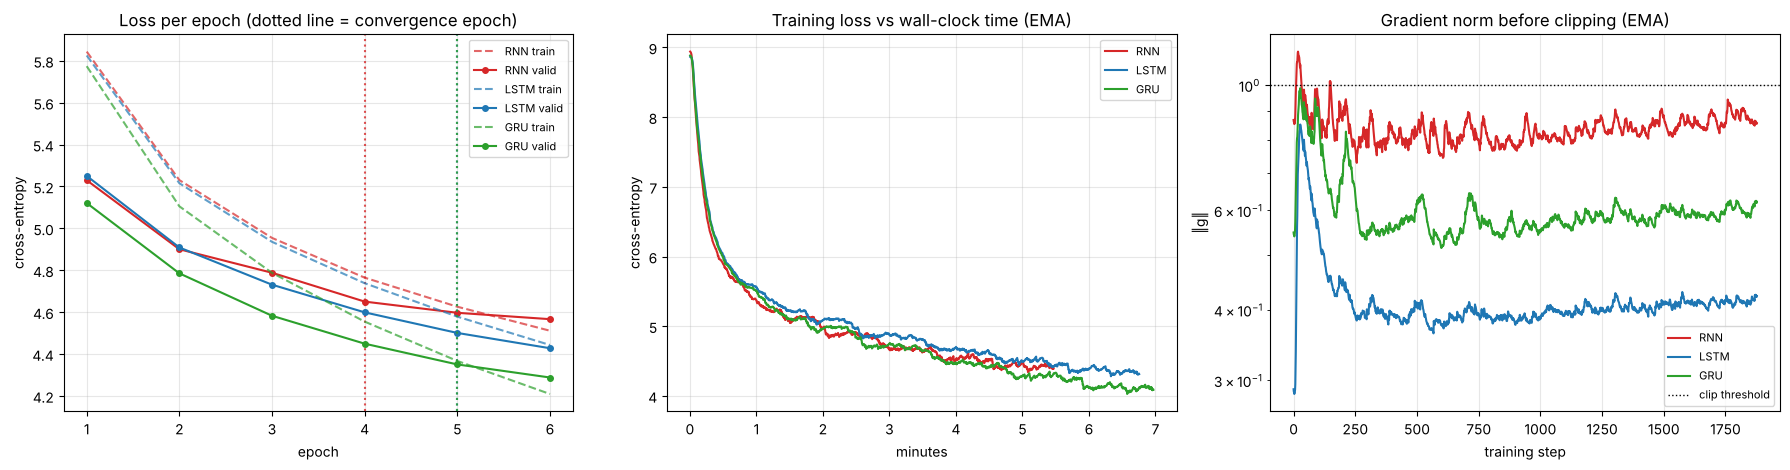

In [12]:
COLORS = {"rnn": "#d62728", "lstm": "#1f77b4", "gru": "#2ca02c"}
TOL = 0.02
def convergence_epoch(valid, tol=TOL):
    b = min(valid)
    return next(i for i, v in enumerate(valid, 1) if v <= b * (1 + tol))

def ema(x, a=0.98):
    out, m = [], x[0]
    for v in x:
        m = a * m + (1 - a) * v; out.append(m)
    return out

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for c, H in results.items():
    ep = range(1, len(H["train"]) + 1)
    ax[0].plot(ep, H["train"], "--", color=COLORS[c], alpha=.7, label=f"{c.upper()} train")
    ax[0].plot(ep, H["valid"], "-o", color=COLORS[c], ms=4, label=f"{c.upper()} valid")
    ce = convergence_epoch(H["valid"])
    ax[0].axvline(ce, color=COLORS[c], ls=":", alpha=.8)
    s = np.array(H["steps"])
    ax[1].plot(s[:, 0] / 60, ema(list(s[:, 1])), color=COLORS[c], label=c.upper())
    ax[2].plot(ema(list(s[:, 2]), .95), color=COLORS[c], label=c.upper())
ax[0].set(title="Loss per epoch (dotted line = convergence epoch)", xlabel="epoch", ylabel="cross-entropy")
ax[1].set(title="Training loss vs wall-clock time (EMA)", xlabel="minutes", ylabel="cross-entropy")
ax[2].set(title="Gradient norm before clipping (EMA)", xlabel="training step", ylabel="‖g‖", yscale="log")
ax[2].axhline(CFG["clip"], color="k", ls=":", lw=1, label="clip threshold")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "convergence.png"), dpi=150); plt.show()

### 6.2 Summary table: quality, convergence and computation time

In [13]:
rows = []
for c, H in results.items():
    be = int(np.argmin(H["valid"])) + 1
    ce = convergence_epoch(H["valid"])
    rows.append({
        "model": c.upper(),
        "params (M)": H["params"] / 1e6,
        "recurrent params (M)": H["recurrent_params"] / 1e6,
        "epochs run": len(H["train"]),
        "best epoch": be,
        f"converged @ epoch (≤{TOL:.0%})": ce,
        "best valid loss": min(H["valid"]),
        "best valid ppl": math.exp(min(H["valid"])),
        "time / epoch (s)": np.mean(H["epoch_time"]),
        "time to converge (min)": sum(H["epoch_time"][:ce]) / 60,
        "total train time (min)": H["total_train_time"] / 60,
        "test decode time (s)": H["decode_time"],
        **{k: v for k, v in H["bleu"].items()},
    })
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(os.path.join(CFG["out_dir"], "summary.csv"))
summary.round(2).T

model,RNN,LSTM,GRU
params (M),4.02,4.81,4.55
recurrent params (M),0.26,1.05,0.79
epochs run,6.00,6.00,6.00
best epoch,6.00,6.00,6.00
converged @ epoch (≤2%),4.00,5.00,5.00
best valid loss,4.57,4.43,4.29
best valid ppl,96.21,83.74,72.82
time / epoch (s),54.35,67.10,69.19
time to converge (min),3.64,5.63,5.83
total train time (min),5.43,6.71,6.92


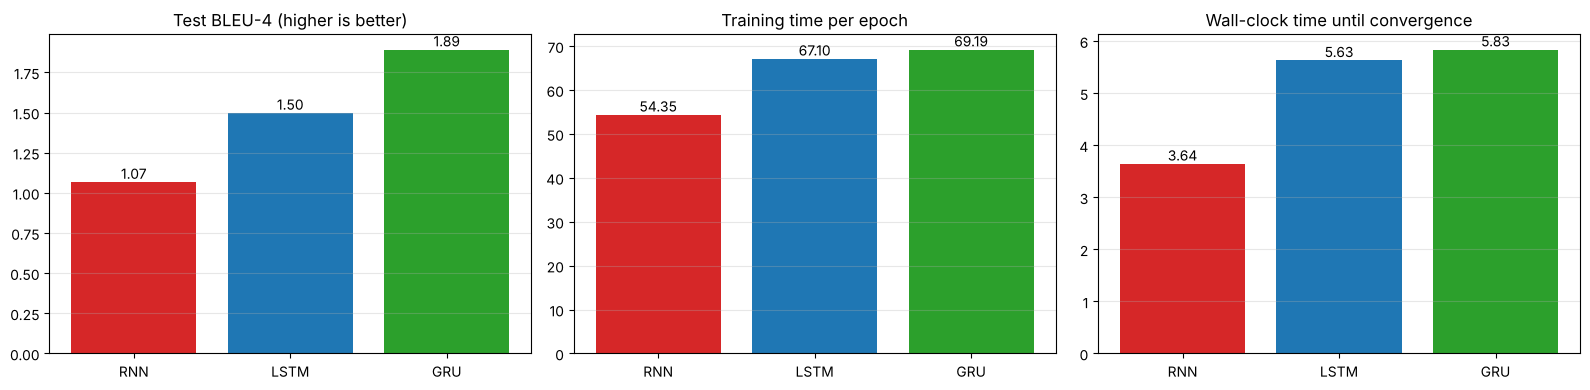

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
names = list(summary.index); cols = [COLORS[n.lower()] for n in names]
for a, col, title in [(ax[0], "BLEU-4", "Test BLEU-4 (higher is better)"),
                      (ax[1], "time / epoch (s)", "Training time per epoch"),
                      (ax[2], "time to converge (min)", "Wall-clock time until convergence")]:
    bars = a.bar(names, summary[col], color=cols)
    a.bar_label(bars, fmt="%.2f"); a.set_title(title); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "comparison.png"), dpi=150); plt.show()

### 6.3 Example translations from the test set

In [15]:
rng_show = random.Random(0)
for i in rng_show.sample(range(len(test_refs)), 8):
    print("DE  :", " ".join(splits["test"][i][0]))
    print("REF :", " ".join(test_refs[i]))
    for c, H in results.items():
        print(f"{c.upper():4s}:", H["hyps"][i])
    print("-" * 100)

DE  : die maxime für die reform ist die notwendigkeit , die branche der finanzdienstleistungen neu zu regulieren .
REF : the common ground of reform is the need to re-regulate the financial services industry .
RNN : the most important of the world’s largest economy is the most important .
LSTM: the us is the most important to the us , the us is the world .
GRU : the second of the european union is the most important challenge of the world .
----------------------------------------------------------------------------------------------------
DE  : in manchen fällen , könnte die antwort lauten : vielleicht sollten sie das ja auch tun .
REF : in some cases , the answer might be : well , perhaps they should .
RNN : in the us , the us has been a lot of the us , but it is not .
LSTM: in the case , the us is not a new way , but it is not enough .
GRU : in the case , the us should be made to be the way , it is no longer .
-------------------------------------------------------------------------

### 6.4 BLEU by sentence length
The encoder vector has a fixed size, so quality is expected to drop on longer sentences. Comparing how quickly each cell
degrades shows how well it keeps long-range information.

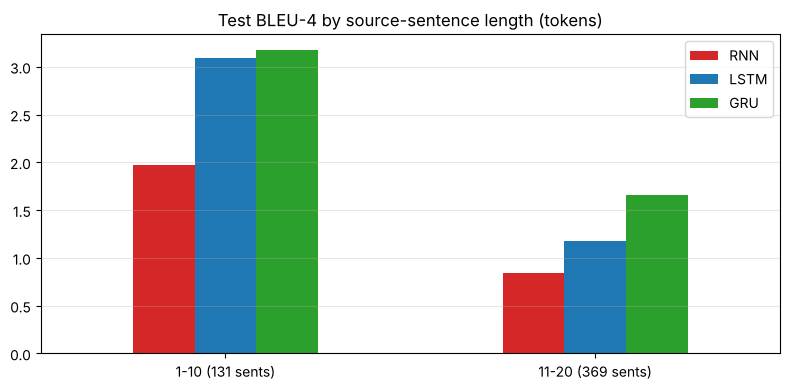

,RNN,LSTM,GRU
1-10 (131 sents),1.98,3.09,3.18
11-20 (369 sents),0.85,1.17,1.65


In [16]:
bins = [(1, 10), (11, 20), (21, 30), (31, 999)]
rows = {}
for c, H in results.items():
    hy = [h.split() for h in H["hyps"]]
    r = {}
    for lo, hi in bins:
        idx = [i for i, (s, _) in enumerate(splits["test"]) if lo <= len(s) <= hi]
        if len(idx) >= 20:
            r[f"{lo}-{hi} ({len(idx)} sents)"] = bleu([hy[i] for i in idx], [test_refs[i] for i in idx])["BLEU-4"]
    rows[c.upper()] = r
by_len = pd.DataFrame(rows)
by_len.plot.bar(color=[COLORS[c.lower()] for c in by_len.columns], figsize=(8, 4), rot=0,
                title="Test BLEU-4 by source-sentence length (tokens)").grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show(); by_len.round(2)

## 7. Extra: seeing the vanishing gradient (slides 23 to 25, 30 to 33, 44 to 49)
The lecture argues that in a vanilla RNN, $\partial E/\partial h_{t}$ contains the product
$\prod_k \partial h_k/\partial h_{k-1}$ of tanh derivatives (each ≤ 1), so it vanishes for words far from the output.
In an LSTM the corresponding factor is roughly the forget-gate activation, which can stay close to 1.

This can be measured directly: take test sentences that all have the same length $S$, compute the loss, and look at
$\lVert \partial \text{Loss} / \partial e_t \rVert$, the size of the gradient that reaches the **embedding of each source
word**, plotted against the word's distance from the end of the encoder (distance 0 is the last word the encoder read,
right next to the decoder). A curve that falls steeply means the model can hardly learn from distant words.

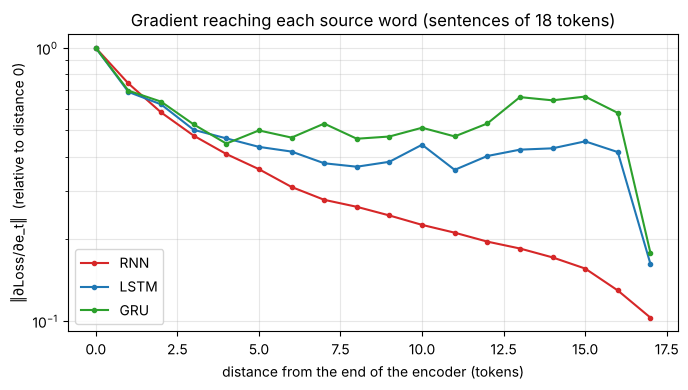

In [17]:
def grad_by_position(model, S=None, n=256):
    lens = collections.Counter(len(s) for s, _ in test_ex)
    S = S or max((l for l in lens if lens[l] >= 32), default=max(lens))
    ex = [e for e in test_ex if len(e[0]) == S][:n]
    src, src_len, tgt = collate(ex)
    src, tgt = src.to(DEV), tgt.to(DEV)
    model.eval()
    with torch.backends.cudnn.flags(enabled=False):               # cuDNN RNN backward needs train mode
        e = model.encoder.emb(src).detach().requires_grad_(True)
        state = model.encoder.forward_emb(e, src_len)
        logits, _ = model.decoder(tgt[:, :-1], state, top_hidden(state))
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1), ignore_index=PAD)
        loss.backward()
    g = e.grad.norm(dim=-1).mean(0).cpu().numpy()                 # (S,) in encoder reading order
    return S, g[::-1]                                             # index 0 = last word read

plt.figure(figsize=(7, 4))
for c, m in models.items():
    S, g = grad_by_position(m)
    plt.semilogy(range(S), g / g[0], "-o", ms=3, color=COLORS[c], label=c.upper())
plt.xlabel("distance from the end of the encoder (tokens)")
plt.ylabel("‖∂Loss/∂e_t‖  (relative to distance 0)")
plt.title(f"Gradient reaching each source word (sentences of {S} tokens)")
plt.grid(alpha=.3, which="both"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(CFG["out_dir"], "vanishing_gradient.png"), dpi=150); plt.show()

## 8. Discussion
*(Fill in with **your** numbers from §6. The prompts below say what to look for and what the lecture predicts. Check
whether your results agree, and explain any case where they don't.)*

**1. Translation quality (BLEU).**
* Lecture prediction: LSTM and GRU beat the vanilla RNN, because the RNN's gradients vanish over long sequences
  (slides 30 to 33). LSTM and GRU should be close to each other (slide 52: "comparable performance, no simple way to
  recommend one or the other").
* My result: RNN = ___ , LSTM = ___ , GRU = ___ BLEU-4. Look at §6.4: does the gap grow with sentence length?
* Context: absolute BLEU is low compared with published WMT systems. This is expected for a word-level seq2seq model
  **without attention**, with a 30k vocabulary, ~150k sentence pairs and greedy decoding. News Commentary is a hard,
  abstract domain (economics and politics). The assignment is about the **relative** comparison of the cells.

**2. Convergence (loss curves, §6.1).**
* Which model reaches the lowest validation loss? At which epoch does each one converge (table column
  `converged @ epoch`)?
* Look at the gap between training and validation loss: when does it widen (overfitting)? That is where early stopping
  picks the best epoch.
* The gradient-norm plot: does the RNN hit the clip threshold more often or more erratically (exploding gradients,
  slide 14)? Do the LSTM and GRU gradients look smoother?

**3. Computation time.**
* Per step, the cost grows with the number of weight blocks: RNN (1) < GRU (3) < LSTM (4). Check this against
  `time / epoch` and `recurrent params`.
* With cuDNN the difference is smaller than 1 : 3 : 4, because the embedding, the softmax over a 30k vocabulary and
  data handling take a large, cell-independent share of the time.
* The fairest number for "which is cheapest to train" is **time to converge**: a cell that is slower per epoch but
  converges in fewer epochs can still win. Slide 52 says GRUs are faster to train. Check it.

**4. Vanishing gradient (§7).**
* Describe the slope of each curve. The lecture predicts the steepest decay for the RNN and much flatter curves for
  the LSTM and GRU (forget/update gates ≈ 1 keep a gradient path open, slides 48 and 49).

**5. Conclusion.**
* Which cell gives the best trade-off of quality and time for this task? Suggested improvements: attention (Bahdanau
  2015, Luong 2015), a bidirectional encoder (slide 58), subword (BPE) vocabularies, beam search, more data and longer
  training.